# Fase 1 · Semana 1: anatomía de una temporada

**Objetivo:** pasar de un partido a una temporada completa y dejar los datos listos para calcular métricas.

1. Descargar y guardar en caché los 380 partidos de la Premier League 2015/16.
2. Controlar la calidad de los datos antes de confiar en ellos.
3. Entender las posesiones.
4. Calcular los minutos jugados de cada jugador.
5. Calcular las primeras métricas por 90 minutos y ver por qué los minutos importan.

Datos: [StatsBomb Open Data](https://github.com/statsbomb/open-data), con atribución a StatsBomb.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from futbol import statsbomb as sbd
from futbol.eventos import COLUMNAS_MINUTOS, minutos_jugados, por_90
from futbol.rutas import FIGURAS, asegurar_carpetas

pd.set_option("display.max_columns", 30)
asegurar_carpetas()

## 1. Descarga y caché

`futbol.statsbomb` descarga cada partido una sola vez y lo guarda en Parquet en `data/raw/statsbomb/`. La primera ejecución tarda unos minutos; las siguientes son locales. Para leer los 380 archivos juntos se usa DuckDB, que une archivos con columnas distintas: no todos los partidos tienen los mismos tipos de evento.

Cargamos solo las columnas que usaremos. La tabla completa tiene más de 100.

In [2]:
comp, temp = sbd.buscar_ids("Premier League", "2015/2016")
partidos = sbd.partidos(comp, temp)

COLUMNAS = sorted(set(COLUMNAS_MINUTOS) | {
    "id", "index", "period", "possession", "possession_team", "play_pattern",
    "location", "shot_outcome", "shot_type", "shot_statsbomb_xg",
})
ev = sbd.eventos(comp, temp, columnas=COLUMNAS)
print(f"{len(partidos)} partidos · {len(ev):,} eventos · {ev.memory_usage(deep=True).sum() / 1e6:,.0f} MB en memoria")

380 partidos · 1,313,773 eventos · 530 MB en memoria


## 2. Control de calidad

Antes de calcular nada hay que confirmar que los datos son lo que creemos. Cuatro chequeos:

In [3]:
# Chequeo 1: la temporada está completa (20 equipos, 38 partidos cada uno, 19 de local)
local = partidos["home_team"].value_counts()
visita = partidos["away_team"].value_counts()
print(f"Equipos: {local.size} · partidos de local por equipo: {local.min()}–{local.max()} · "
      f"de visita: {visita.min()}–{visita.max()}")

Equipos: 20 · partidos de local por equipo: 19–19 · de visita: 19–19


In [4]:
# Chequeo 2: cuántos eventos tiene cada partido (un valor muy bajo delataría un partido incompleto)
ev.groupby("match_id").size().describe().round(0)

count     380.0
mean     3457.0
std       285.0
min      2670.0
25%      3264.0
50%      3454.0
75%      3644.0
max      4264.0
dtype: float64

In [5]:
# Chequeo 3: las acciones con balón deben tener ubicación; los eventos administrativos, no
sin_ubicacion = ev.assign(sin_ubicacion=ev["location"].isna()).groupby("type")["sin_ubicacion"].mean()
sin_ubicacion.sort_values(ascending=False).head(12).round(3)

type
Bad Behaviour      1.000
Substitution       1.000
Half End           1.000
Half Start         1.000
Starting XI        1.000
Player On          1.000
Tactical Shift     1.000
Player Off         1.000
Injury Stoppage    1.000
Goal Keeper        0.002
50/50              0.000
Dribble            0.000
Name: sin_ubicacion, dtype: float64

In [6]:
# Chequeo 4: los goles de los eventos deben coincidir con el marcador oficial.
# Un gol es un tiro con resultado «Goal» o un autogol a favor («Own Goal For»).
goles_ev = (
    ev[(ev["shot_outcome"] == "Goal") | (ev["type"] == "Own Goal For")]
    .groupby(["match_id", "team"]).size().rename("goles")
)
control = partidos[["match_id", "home_team", "away_team", "home_score", "away_score"]].copy()
control["goles_local"] = [goles_ev.get((m, t), 0) for m, t in zip(control["match_id"], control["home_team"])]
control["goles_visita"] = [goles_ev.get((m, t), 0) for m, t in zip(control["match_id"], control["away_team"])]
coinciden = (control["goles_local"] == control["home_score"]) & (control["goles_visita"] == control["away_score"])
print(f"Partidos cuyo marcador coincide con los eventos: {coinciden.sum()} de {len(control)}")
print(f"Goles en la temporada: {int(control[['home_score', 'away_score']].sum().sum())}")

Partidos cuyo marcador coincide con los eventos: 380 de 380
Goles en la temporada: 1026


## 3. Posesiones

Cada evento trae el número de posesión y el equipo que la tiene. Agrupar por posesión permite estudiar secuencias en vez de acciones sueltas. El `play_pattern` del primer evento dice cómo empezó la posesión.

In [7]:
posesiones = ev.groupby(["match_id", "possession"]).agg(
    equipo=("possession_team", "first"),
    inicio=("play_pattern", "first"),
    eventos=("id", "size"),
)
por_partido = posesiones.groupby("match_id").size()
print(f"Posesiones por partido: mediana {por_partido.median():.0f} "
      f"(rango {por_partido.min()}–{por_partido.max()}) · eventos por posesión: mediana {posesiones['eventos'].median():.0f}")
posesiones["inicio"].value_counts(normalize=True).round(3).rename("proporción")

Posesiones por partido: mediana 189 (rango 142–239) · eventos por posesión: mediana 13


inicio
Regular Play      0.397
From Throw In     0.244
From Free Kick    0.133
From Goal Kick    0.088
From Corner       0.057
From Keeper       0.032
From Kick Off     0.025
From Counter      0.018
Other             0.005
Name: proporción, dtype: float64

## 4. Minutos jugados

Los minutos son la **exposición** de cada jugador: sin ellos no se puede comparar a un titular con un suplente. `minutos_jugados()` los calcula desde los eventos: los titulares entran en el minuto 0 y cada jugador sale por cambio, por expulsión o al final del partido (el último evento, que incluye el tiempo agregado).

In [8]:
minutos = minutos_jugados(ev[COLUMNAS_MINUTOS])

# Control: en cada partido, un equipo suma unos 11 jugadores × duración (menos si hubo expulsiones)
por_equipo = minutos.groupby(["match_id", "team"])["minutos"].sum()
duracion = minutos.groupby("match_id")["salida"].max()
jugadores_en_cancha = por_equipo / duracion.reindex(por_equipo.index.get_level_values("match_id")).to_numpy()
jugadores_en_cancha.describe().round(2)

count    760.00
mean      10.97
std        0.12
min        9.59
25%       11.00
50%       11.00
75%       11.00
max       11.00
Name: minutos, dtype: float64

In [9]:
temporada = (
    minutos.groupby("player_id")
    .agg(jugador=("player", "first"), partidos=("match_id", "nunique"), minutos=("minutos", "sum"))
    .sort_values("minutos", ascending=False)
)
print(f"{len(temporada)} jugadores usados · {(temporada['minutos'] >= 900).sum()} con 900 minutos o más")
temporada.head(5).round(0)

550 jugadores usados · 327 con 900 minutos o más


,jugador,partidos,minutos
player_id,,,
3815,Kasper Schmeichel,38,3594.0
3813,Wes Morgan,38,3594.0
3344,Andrew Surman,38,3592.0
20005,Toby Alderweireld,38,3569.0
3522,Heurelho da Silva Gomes,38,3554.0


## 5. Primeras métricas por 90 minutos

Usamos goles y xG **sin penales** (npG, npxG): un penal vale cerca de 0,78 xG y lo patea quien el equipo designe, así que distorsiona la comparación entre jugadores.

In [10]:
tiros = ev[(ev["type"] == "Shot") & (ev["shot_type"] != "Penalty")].astype({"player_id": int})
ataque = tiros.groupby("player_id").agg(
    tiros=("id", "size"),
    npG=("shot_outcome", lambda s: (s == "Goal").sum()),
    npxG=("shot_statsbomb_xg", "sum"),
)
jugadores = temporada.join(ataque).fillna({"tiros": 0, "npG": 0, "npxG": 0})
jugadores["npG_90"] = por_90(jugadores["npG"], jugadores["minutos"])
jugadores["npxG_90"] = por_90(jugadores["npxG"], jugadores["minutos"])

columnas_tabla = ["jugador", "minutos", "npG", "npG_90", "npxG_90"]
print("Top 5 en goles por 90, sin mínimo de minutos:")
display(jugadores.sort_values("npG_90", ascending=False)[columnas_tabla].head(5).round(2))
print("Top 10 en goles por 90, con 900 minutos o más:")
jugadores[jugadores["minutos"] >= 900].sort_values("npG_90", ascending=False)[columnas_tabla].head(10).round(2)

Top 5 en goles por 90, sin mínimo de minutos:


,jugador,minutos,npG,npG_90,npxG_90
player_id,,,,,
42702,Modibo Maïga,42.65,1.0,2.11,0.95
3708,Kelechi Promise Iheanacho,841.37,8.0,0.86,0.54
3237,Sergio Leonel Agüero del Castillo,2422.85,20.0,0.74,0.51
3529,Daniel Andre Sturridge,1022.28,8.0,0.70,0.45
5556,Miguel Arturo Layún Prado,134.13,1.0,0.67,0.17


Top 10 en goles por 90, con 900 minutos o más:


,jugador,minutos,npG,npG_90,npxG_90
player_id,,,,,
3237,Sergio Leonel Agüero del Castillo,2422.85,20.0,0.74,0.51
3529,Daniel Andre Sturridge,1022.28,8.0,0.70,0.45
3604,Olivier Giroud,2550.23,15.0,0.53,0.43
10960,Jamie Vardy,3267.05,19.0,0.52,0.48
10955,Harry Kane,3486.65,20.0,0.52,0.46
3337,Jermain Defoe,2673.20,14.0,0.47,0.42
4271,Andy Carroll,1534.73,8.0,0.47,0.32
3385,Alexis Alejandro Sánchez Sánchez,2519.07,13.0,0.46,0.40
3289,Romelu Lukaku Menama,3299.48,17.0,0.46,0.45


### El embudo: por qué los minutos importan

Si todos los jugadores tuvieran la misma tasa real λ, su tasa observada por 90 tendría varianza 90λ/t. La banda gris marca ±2 errores estándar alrededor de la tasa media de la liga: con pocos minutos es tan ancha que casi cualquier valor es compatible con el azar. Con muchos minutos la banda se estrecha: los puntos que siguen por encima difícilmente se explican por suerte y reflejan diferencias reales entre jugadores.

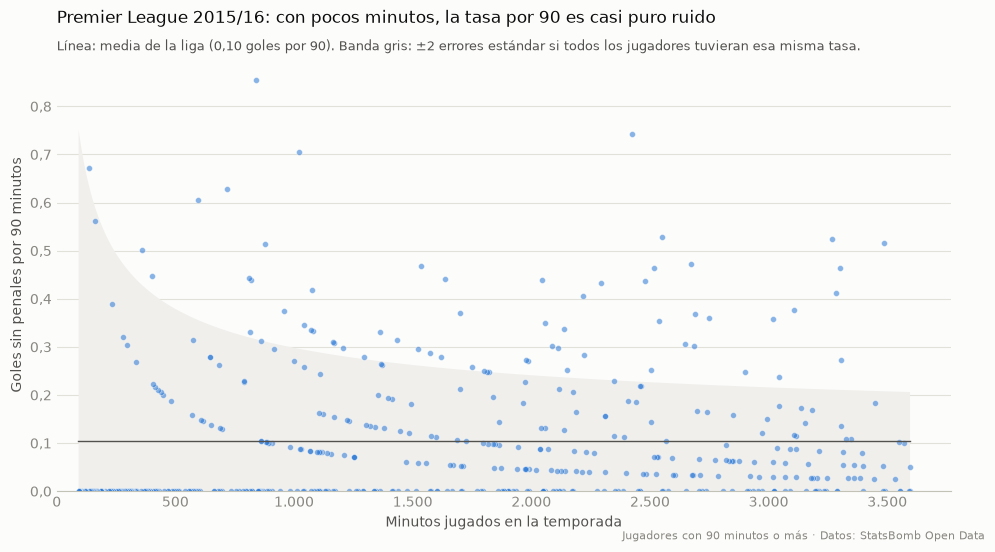

In [11]:
AZUL, TINTA, TINTA_2, MUTED, GRILLA, BANDA = "#2a78d6", "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#f0efec"

con_minutos = jugadores[jugadores["minutos"] >= 90]
tasa_liga = 90 * con_minutos["npG"].sum() / con_minutos["minutos"].sum()
t = np.linspace(90, con_minutos["minutos"].max(), 300)
ee = np.sqrt(90 * tasa_liga / t)

fig, ax = plt.subplots(figsize=(10, 5.5), facecolor="#fcfcfb")
ax.set_facecolor("#fcfcfb")
ax.fill_between(t, np.clip(tasa_liga - 2 * ee, 0, None), tasa_liga + 2 * ee, color=BANDA, linewidth=0)
ax.plot(t, np.full_like(t, tasa_liga), color=TINTA_2, linewidth=1)
ax.scatter(con_minutos["minutos"], con_minutos["npG_90"], s=18, color=AZUL, alpha=0.55,
           edgecolors="#fcfcfb", linewidths=0.5)

coma = lambda texto: texto.replace(",", "_").replace(".", ",").replace("_", ".")
ax.set_xlabel("Minutos jugados en la temporada", color=TINTA_2)
ax.set_ylabel("Goles sin penales por 90 minutos", color=TINTA_2)
ax.set_title("Premier League 2015/16: con pocos minutos, la tasa por 90 es casi puro ruido",
             loc="left", fontsize=12, color=TINTA, pad=26)
ax.text(0, 1.02, f"Línea: media de la liga ({coma(f'{tasa_liga:.2f}')} goles por 90). Banda gris: ±2 errores estándar "
                 "si todos los jugadores tuvieran esa misma tasa.",
        transform=ax.transAxes, fontsize=9.5, color=TINTA_2)
ax.xaxis.set_major_formatter(lambda x, _: coma(f"{x:,.0f}"))
ax.yaxis.set_major_formatter(lambda y, _: coma(f"{y:.1f}"))
ax.grid(axis="y", color=GRILLA, linewidth=0.8)
ax.set_axisbelow(True)
for lado in ("top", "right", "left"):
    ax.spines[lado].set_visible(False)
ax.spines["bottom"].set_color("#c3c2b7")
ax.tick_params(colors=MUTED, length=0)
ax.set_xlim(0, None)
ax.set_ylim(0, None)
fig.text(0.99, 0.01, "Jugadores con 90 minutos o más · Datos: StatsBomb Open Data", ha="right", fontsize=8, color=MUTED)
fig.tight_layout()
fig.savefig(FIGURAS / "f1_embudo_goles_por_90.png", dpi=150, bbox_inches="tight")
plt.show()

## 6. Qué sigue

- **Semana 2:** estandarizar los eventos a SPADL y calcular métricas por 90 y por posesión (pases progresivos, PPDA, *field tilt*).
- **Para pensar:** en el embudo, ¿qué jugadores con más de 2.000 minutos quedan bajo la banda? ¿Son malos definidores o es que su posición no es de ataque?